In [1]:
from sklearn.datasets import fetch_california_housing
data = fetch_california_housing(as_frame=True)
df = data.frame

In [2]:
from sklearn.model_selection import train_test_split
X = df.drop(columns='MedHouseVal')
y = df['MedHouseVal']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)
print(y_train.shape, y_test.shape)

(16512, 8) (4128, 8)
(16512,) (4128,)


In [3]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

In [4]:
ols_pipeline = Pipeline([
    ('scaler',StandardScaler()),
    ('model',LinearRegression()),
])

In [5]:
scores_ols = cross_val_score(
    ols_pipeline,
    X_train,
    y_train,
    cv = 5,
    scoring='neg_root_mean_squared_error'
)
rmse_ols = -scores_ols
print(rmse_ols)
print(f'RMSE moyen:{rmse_ols.mean():.3f} +/- {rmse_ols.std():.3f}')

[0.72115555 0.70872616 0.7214877  0.71266905 0.73859747]
RMSE moyen:0.721 +/- 0.010


In [6]:
import numpy as np
from sklearn.linear_model import RidgeCV
alphas = np.logspace(-5, 2, 50)
ridge_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', RidgeCV(alphas=alphas, cv=5))
])

In [7]:
scores_ridge = cross_val_score(
    ridge_pipeline,
    X_train,
    y_train,
    cv=5,
    scoring="neg_root_mean_squared_error",
)
rmse_ridge = -scores_ridge
print(rmse_ridge)
print(f"RMSE moyen : {rmse_ridge.mean():.3f} (+/- {rmse_ridge.std():.3f})")

[0.72119668 0.70876472 0.7215198  0.71266985 0.73822901]
RMSE moyen : 0.720 (+/- 0.010)


In [8]:
from sklearn.linear_model import LassoCV
lasso_pipeline = Pipeline([
    ('scaler',StandardScaler()),
    ('model', LassoCV(alphas=alphas,cv=5,random_state=42,max_iter=10000)),
])

In [9]:
scores_lasso = cross_val_score(
    lasso_pipeline ,
    X_train,
    y_train,
    cv = 5,
    scoring = 'neg_root_mean_squared_error'
)
rmse_lasso = -scores_lasso
print(rmse_lasso)
print(f'RMSE moyen: {rmse_lasso.mean():.3f} +/- {rmse_lasso.std():.3f}')

[0.72189338 0.70933917 0.72171683 0.71258884 0.74103287]
RMSE moyen: 0.721 +/- 0.011


In [10]:
ols_pipeline.fit(X_train, y_train)
ridge_pipeline.fit(X_train, y_train)
lasso_pipeline.fit(X_train, y_train)

print(f"Alpha Ridge : {ridge_pipeline['model'].alpha_:.4e}")
print(f"Alpha Lasso : {lasso_pipeline['model'].alpha_:.4f}")

Alpha Ridge : 1.0000e-05
Alpha Lasso : 0.0007


In [11]:
import pandas as pd
coefficients = pd.DataFrame({
    'OLS': ols_pipeline['model'].coef_,
    'Ridge': ridge_pipeline['model'].coef_,
    'Lasso': lasso_pipeline['model'].coef_,
},
index = X_train.columns,                                                     
)
print(coefficients.round(3))


              OLS  Ridge  Lasso
MedInc      0.854  0.854  0.851
HouseAge    0.123  0.123  0.123
AveRooms   -0.294 -0.294 -0.285
AveBedrms   0.339  0.339  0.330
Population -0.002 -0.002 -0.001
AveOccup   -0.041 -0.041 -0.040
Latitude   -0.897 -0.897 -0.889
Longitude  -0.870 -0.870 -0.861


In [12]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_pred = ridge_pipeline.predict(X_test)
rmse = np.sqrt(mean_squared_error(y_test,y_pred))
mae = mean_absolute_error(y_test,y_pred)
r2 = r2_score(y_test,y_pred)

print(f'RMSE:{rmse:.4f}')
print(f'MAE: {mae:.4f}')
print(f'R2: {r2:.4f}')

RMSE:0.7456
MAE: 0.5332
R2: 0.5758


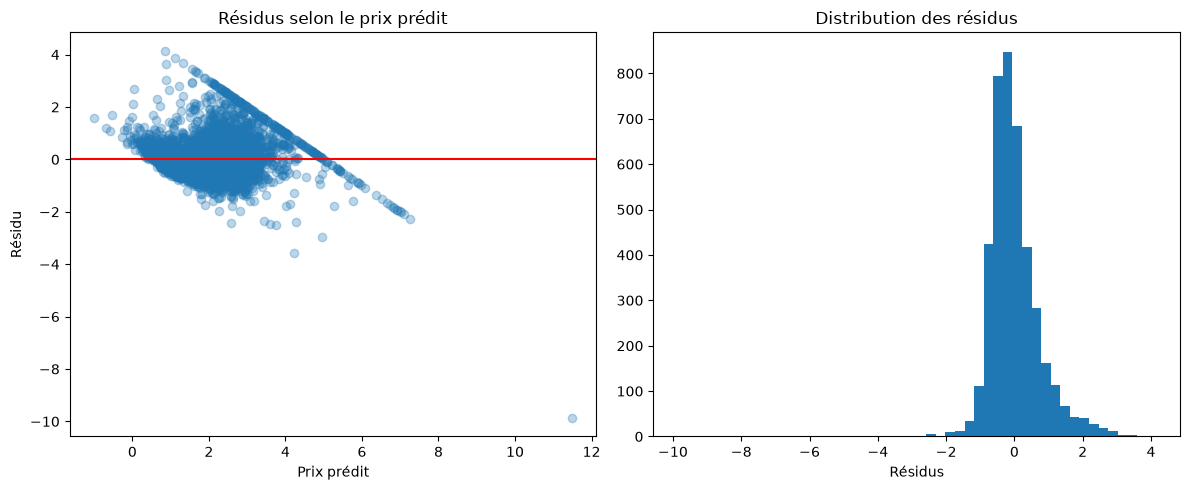

In [13]:
import matplotlib.pyplot as plt

residuals = y_test - y_pred
fig,axes = plt.subplots(1, 2, figsize=(12,5))
axes[0].scatter(y_pred, residuals, alpha=0.3)
axes[0].axhline(0, color='red')
axes[0].set_xlabel('Prix prédit')
axes[0].set_ylabel('Résidu')
axes[0].set_title('Résidus selon le prix prédit')

axes[1].hist(residuals, bins=50)
axes[1].set_xlabel('Résidus')
axes[1].set_title('Distribution des résidus')

plt.tight_layout()
plt.show()